In [9]:
from wtlike import check_data
from wtlike import *
from pylib import data_setup
from importlib import reload
from pylib import mc_dev; reload(mc_dev)
from pylib.mc_dev import (sim_design_thoughts, check_step, BBsim, p_view, show, show_date,
                          capture_hide, plt, sns, pd, np)
from utilities.ipynb_docgen import show_fig
from wtlike import WtLike, Timer
show_date()

<h5 style="text-align:right; margin-right:15px"> 2026-11-16 23:34</h5>

In [18]:
# show(sim_design_thoughts, summary='Simulation design')
name = '4FGL J0056.3-0935' # strong single-step
show(f"""Choose {name} to use for MC study""")
with capture_hide(f'Source setup output for {name}') as printout:
    wtl = WtLike(name, time_bins=(0,0,30),clear=False)
with capture_hide(f'Source setup output for {name}') as printout:
    wtl2 = WtLike(name, time_bins=(0,0,31),clear=False)
show(printout)
show(f'Will use its `{len(wtl.photons)}` weight values for simulation') 

Choose 4FGL J0056.3-0935 to use for MC study

<utilities.ipynb_docgen.doc_formatter.<locals>.MimeBundleObject at 0x7ce1060fb770>

Will use its `80533` weight values for simulation

## BB with data

Bayesian Blocks: partitioning 207  cells using LikelihoodFitness with penalty 5%
	found 2 / 207 blocks.
LightCurve: Loaded 2 / 2 cells for fitting


<utilities.ipynb_docgen.doc_formatter.<locals>.MimeBundleObject at 0x7ce1060fb770>
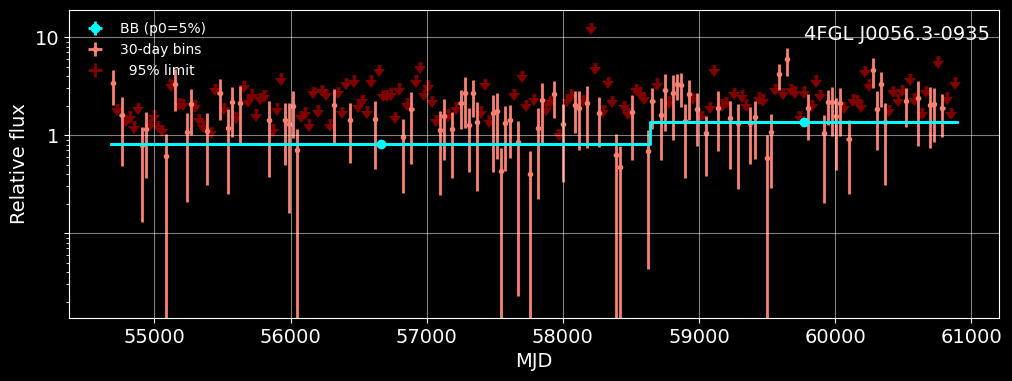

TSvar = 19.0 for 2 blocks

Single step observed at MJD 58643.0, 
ratio 1.67

In [20]:
show(f"""## BB with data""")
plt.style.use('dark_background')
bb_full = wtl.bb_view()
bb_full.plot(log=True);
show(plt.gcf())

step = check_step(bb_full)
# bb_full_r = wtl.bb_view(reverse=True)
# check_step(bb_full_r)

# Run Multiple Simulations and compare data

In [ ]:
from wtlike import WtLike
from pylib.mc_dev import BBsim, check_step, p_view
from utilities.ipynb_docgen import show
import matplotlib.pyplot as plt
import pandas as pd
from IPython.utils.capture import capture_output

# Adjust these parameters and rerun this cell.
sweep_source_name = name
rng = np.random.default_rng(seed = 62508)
bin_widths_days = np.round(rng.normal(loc=30, scale=10, size=1000).clip(5, 100))
num_partitions = 100
nproc = 8
p0 = 0.05
partition_delta_days = 1500
reverse = True

sweep_results = []
sweep_samples = []

for width_index, bin_width_days in enumerate(bin_widths_days, start=1):
    try:
        with capture_output():
            sweep_wtl = WtLike(
                sweep_source_name,
                time_bins=(0, 0, bin_width_days),
                clear=False,
            )

            sweep_bb = sweep_wtl.bb_view(p0=p0)
            sweep_step = check_step(sweep_bb, showit=False)

            sweep_range = (
                sweep_step.time - partition_delta_days,
                sweep_step.time + partition_delta_days,
            )
            sweep_partition = p_view(sweep_wtl, *sweep_range)

            _, simulation_results = BBsim.run_many(
                sweep_partition,
                seeds=range(num_partitions),
                nproc=nproc,
                step_time=sweep_step.time,
            )

            sweep_samples.append(
                simulation_results.assign(
                    bin_width_days=bin_width_days,
                    true_step_time=sweep_step.time,
                )
            )
            sweep_results.append({
                "bin_width_days": bin_width_days,
                "input_cells": len(sweep_wtl.cells),
                "partition_cells": len(sweep_partition.cells),
                "mean_blocks": simulation_results.nbb.mean(),
                "mean_step_time": simulation_results.time.mean(),
                "mean_ts": simulation_results.ts.mean(),
                "mean_ratio": simulation_results.ratio.mean(),
            })
        print(f"{bin_width_days}d: done")

    except ValueError as e:
        print(f"{bin_width_days}d: skipped ({' '.join(str(e).split())})")
        continue
    except KeyboardInterrupt:
        print(f"{bin_width_days}d: interrupted")
        break
    except Exception as e:
        print(f"{bin_width_days}d: failed ({type(e).__name__}: {' '.join(str(e).split())})")
        continue

sweep_summary = pd.DataFrame(sweep_results)
display(sweep_summary)

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
metrics = [
    ("mean_blocks", "Average number of blocks"),
    ("mean_step_time", "Average detected step time (MJD)"),
    ("mean_ts", "Average variability TS"),
    ("mean_ratio", "Average step ratio"),
]
for ax, (column, ylabel) in zip(axes.flat, metrics):
    ax.plot(sweep_summary.bin_width_days, sweep_summary[column], "o-")
    ax.set(xlabel="Bin width (days)", ylabel=ylabel)
    ax.grid(alpha=0.3)
fig.suptitle(
    f"Averages over {num_partitions:,} Bayesian-block partitions per bin width"
)
fig.tight_layout()
show(fig)

In [ ]:
if not sweep_samples:
    raise ValueError("Cell 7 did not produce any simulation results to average.")

all_simulations = pd.concat(sweep_samples, ignore_index=True)
average_results = all_simulations[["nbb", "time", "ts", "ratio"]].mean()
print("Average results across all simulations:")
display(average_results.rename({
    "nbb": "Average number of blocks",
    "time": "Average detected step time (MJD)",
    "ts": "Average variability TS",
    "ratio": "Average step ratio",
}).to_frame(name="mean").round(3))

# Overlay the ensemble-average step on the observed light curve from cell 6.
bb_full.plot(log=True)
ax = plt.gca()
fits = bb_full.fits
start_mjd = float(fits.t.iloc[0] - fits.tw.iloc[0] / 2)
end_mjd = float(fits.t.iloc[-1] + fits.tw.iloc[-1] / 2)
mean_step_time = float(average_results["time"])
mean_ratio = float(average_results["ratio"])
baseline_flux = float(fits.fit.iloc[0].flux)

ax.step(
    [start_mjd, mean_step_time, end_mjd],
    [baseline_flux, baseline_flux * mean_ratio, baseline_flux * mean_ratio],
    where="pre",
    color="darkorange",
    linestyle="--",
    linewidth=2,
    label="Ensemble-average simulated step",
)
ax.axvline(mean_step_time, color="darkorange", linestyle=":", alpha=0.8)
ax.legend()
fig = plt.gcf()
fig.suptitle("Observed light curve with ensemble-average simulated step")
show(fig)